# Polynomial Regression from Scratch

This project implements quadratic polynomial regression using manually derived
gradients and NumPy. It explores how gradient descent learns model parameters
and how optimization choices affect convergence and predictive performance.

## Model

The model represents a curved relationship between an input and its target:

$$
\hat{y} = \theta_0 + \theta_1 x + \theta_2 x^2
$$

Although the prediction is nonlinear in the input, it is linear in the
parameters. With mean squared error as the objective, this produces a convex
optimization problem.

## Objectives

- Derive and implement the gradients of mean squared error.
- Train polynomial regression using full-batch and mini-batch gradient descent.
- Examine convergence through loss curves and parameter trajectories.
- Explore the effect of L2 regularization.
- Compare the custom implementation with NumPy, SciPy, and scikit-learn.

## Approach

Experiments use reproducible synthetic data with a known quadratic relationship
and Gaussian noise. The core model and optimization algorithms are implemented
manually; library fitting methods serve as reference solutions.

## Notebook Guide

1. Generate synthetic data and define the extrapolation split.
2. Define the model, MSE, and analytical gradients; verify the derivatives.
3. Fit full-batch gradient descent and inspect loss and parameter movement.
4. Verify agreement with NumPy, SciPy, and scikit-learn.
5. Explore mini-batch optimization and L2 regularization.
6. Compare results and discuss limitations.

Run all cells from top to bottom using the project environment. Figures are
saved automatically to the project's `figures/` folder; rerunning overwrites
files with the same names. Required packages are NumPy, Matplotlib, SciPy,
scikit-learn, and IPython, with a Jupyter-compatible Python kernel.

## Synthetic Data Generation

We generate 100 evenly spaced inputs and normalize them to the interval
[-1, 1] before constructing the target:

$$
x = u / 10,\qquad y = 1 + 2x + 3x^2 + \epsilon
$$

Here $u$ spans [-10, 10], $x$ is the normalized input used throughout
the model equations, and $\epsilon \sim \mathcal{N}(0, 3^2)$.

The true coefficients in the normalized input space are [1, 2, 3].
Normalization keeps polynomial features small, which helps numerical stability
during gradient descent.

Targets are generated from normalized inputs. This defines a quadratic
experiment on [-1, 1], rather than preserving targets generated on [-10, 10].

A fixed random seed makes the generated observations reproducible.

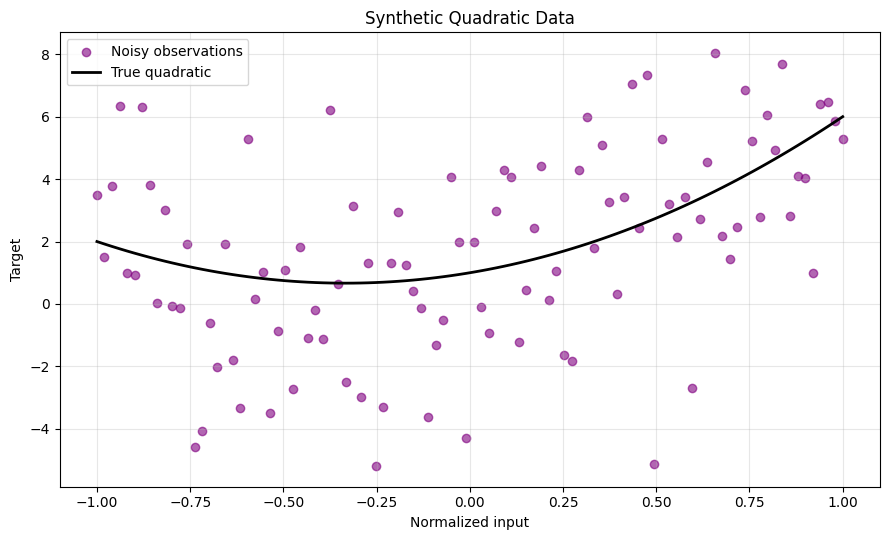

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path


def find_project_root():
    """Locate the project from a kernel started in its root or notebooks folder."""
    current = Path.cwd().resolve()
    for candidate in (current, *current.parents):
        notebook = candidate / "notebooks" / "polynomial_regression_from_scratch.ipynb"
        if notebook.is_file():
            return candidate
    raise FileNotFoundError(
        "Open this notebook inside the project root or its notebooks folder."
    )


PROJECT_ROOT = find_project_root()
FIGURES_DIR = PROJECT_ROOT / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.figsize": (9, 5.5),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "savefig.facecolor": "white",
})


def save_figure(fig, filename):
    """Export the current plot as a reproducible 200-DPI PNG."""
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / filename, dpi=200, bbox_inches="tight")


# Generate reproducible observations.
np.random.seed(42)

N_SAMPLES = 100
INPUT_SCALE = 10.0
NOISE_STD = 3.0
TRUE_THETA = np.array([1.0, 2.0, 3.0])

X = np.linspace(-10.0, 10.0, N_SAMPLES)
X_scaled = X / INPUT_SCALE

# Construct the target in the normalized input space.
y_true = (
    TRUE_THETA[0]
    + TRUE_THETA[1] * X_scaled
    + TRUE_THETA[2] * X_scaled**2
)
epsilon = np.random.normal(0.0, NOISE_STD, size=N_SAMPLES)
y = y_true + epsilon

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(X_scaled, y, color="purple", alpha=0.6, label="Noisy observations")
ax.plot(X_scaled, y_true, color="black", linewidth=2, label="True quadratic")
ax.set(
    title="Synthetic Quadratic Data",
    xlabel="Normalized input",
    ylabel="Target",
)
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
save_figure(plt.gcf(), "synthetic_quadratic_data.png")
plt.show()
plt.close()

## Training and Test Split

The observations are ordered by input value. We use the first 80% for
training and the remaining 20% for testing, without shuffling.

- Training inputs span approximately -1.00 to 0.60.
- Test inputs span approximately 0.62 to 1.00.

Because all test inputs lie beyond the training range, this evaluates
extrapolation over the held-out upper portion of the input domain.

Test MSE measures performance on these 20 observations. It does not establish
performance across other datasets, random seeds, or input ranges.

Training samples: 80
Test samples: 20
Training input range: [-1.000, 0.596]
Test input range: [0.616, 1.000]


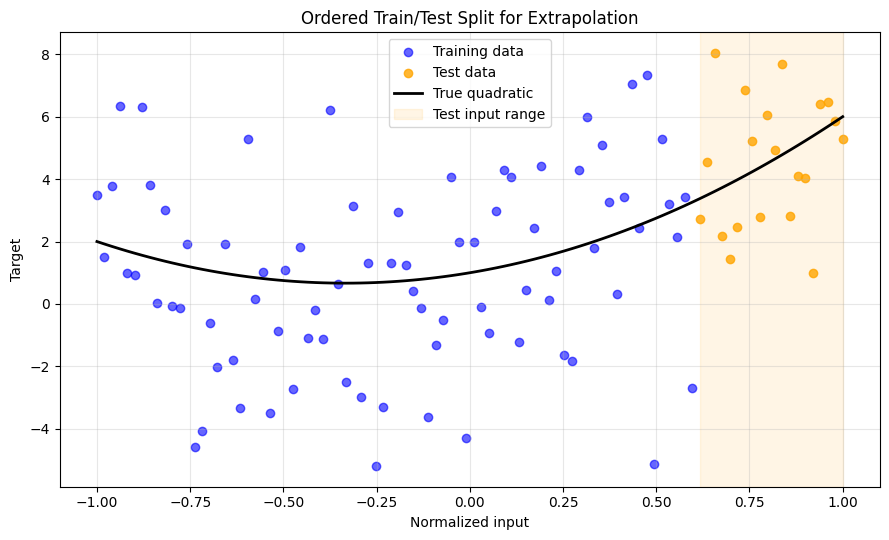

In [2]:
# Preserve input order to evaluate extrapolation.
TRAIN_FRACTION = 0.8
train_size = int(TRAIN_FRACTION * len(X_scaled))

X_train, X_test = X_scaled[:train_size], X_scaled[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

print(f"Training samples: {len(X_train)}")
print(f"Test samples: {len(X_test)}")
print(f"Training input range: [{X_train.min():.3f}, {X_train.max():.3f}]")
print(f"Test input range: [{X_test.min():.3f}, {X_test.max():.3f}]")

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(X_train, y_train, color="blue", alpha=0.6, label="Training data")
ax.scatter(X_test, y_test, color="orange", alpha=0.8, label="Test data")
ax.plot(X_scaled, y_true, color="black", linewidth=2, label="True quadratic")

# Shade the input interval reserved for testing.
ax.axvspan(
    X_test.min(), X_test.max(),
    color="orange", alpha=0.1, label="Test input range",
)

ax.set(
    title="Ordered Train/Test Split for Extrapolation",
    xlabel="Normalized input",
    ylabel="Target",
)
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
save_figure(plt.gcf(), "extrapolation_split.png")
plt.show()
plt.close()

## Quadratic Model

The model predicts targets using an intercept, a linear term, and a
quadratic term:

$$
\hat{y} = \theta_0 + \theta_1 x + \theta_2 x^2
$$

The design matrix contains one row per observation and columns [1, x, x²].
Multiplying it by the parameter vector produces all predictions at once.
Here, x denotes the normalized input.

In [3]:
def design_matrix(X):
    """Construct quadratic features [1, x, x²] for a 1D input array."""
    return np.column_stack((np.ones_like(X), X, X**2))


def predict(X, theta):
    """Predict targets using parameters ordered as intercept, linear, quadratic."""
    return design_matrix(X) @ theta

## Mean Squared Error

Mean squared error measures the average squared prediction error:

$$
L(\theta) = \frac{1}{n}\sum_{i=1}^{n}(\hat{y}_i-y_i)^2
$$

Training minimizes this objective. Evaluation uses the same metric on
held-out observations.

In [4]:
def mse_loss(y_true, y_pred):
    """Return the mean squared prediction error."""
    return np.mean((y_pred - y_true)**2)

## Analytical Gradients

Let $e_i = \hat{y}_i - y_i$. Differentiating MSE gives:

$$
\frac{\partial L}{\partial\theta_0} = \frac{2}{n}\sum_i e_i
$$

$$
\frac{\partial L}{\partial\theta_1} = \frac{2}{n}\sum_i e_i x_i
$$

$$
\frac{\partial L}{\partial\theta_2} = \frac{2}{n}\sum_i e_i x_i^2
$$

These derivatives are implemented explicitly with NumPy, without automatic
differentiation. A central finite-difference check independently approximates
each derivative to verify the implementation.

In [5]:
def compute_gradients(X, y, theta):
    """Compute the analytical MSE gradient for quadratic regression."""
    error = predict(X, theta) - y
    n = len(y)

    return (2.0 / n) * np.array([
        np.sum(error),
        np.sum(error * X),
        np.sum(error * X**2),
    ])


def numerical_gradients(X, y, theta, step=1e-5):
    """Approximate the gradient using central finite differences."""
    gradients = np.zeros_like(theta, dtype=float)

    for j in range(len(theta)):
        theta_plus = theta.copy()
        theta_minus = theta.copy()
        theta_plus[j] += step
        theta_minus[j] -= step

        loss_plus = mse_loss(y, predict(X, theta_plus))
        loss_minus = mse_loss(y, predict(X, theta_minus))
        gradients[j] = (loss_plus - loss_minus) / (2.0 * step)

    return gradients


# Check at nonzero parameters to exercise every model term.
theta_check = np.array([0.5, -0.5, 1.0])
analytical = compute_gradients(X_train, y_train, theta_check)
numerical = numerical_gradients(X_train, y_train, theta_check)

print("Analytical gradient:", analytical)
print("Numerical gradient: ", numerical)
print("Maximum absolute difference:", np.max(np.abs(analytical - numerical)))

np.testing.assert_allclose(
    analytical, numerical, rtol=1e-6, atol=1e-7
)
print("Gradient check passed.")

Analytical gradient: [-0.28063014 -0.75713264 -0.04100844]
Numerical gradient:  [-0.28063014 -0.75713264 -0.04100844]
Maximum absolute difference: 1.7164630827792848e-11
Gradient check passed.


## Full-Batch Gradient Descent

Each update uses all training observations:

$$
\theta \leftarrow \theta - \eta \nabla L(\theta)
$$

Training stops when the gradient norm falls below a specified tolerance,
or when the maximum number of updates is reached.

We record training MSE and parameter values, including initialization.
These histories support convergence analysis and visualization.

Gradient clipping is omitted so updates follow the analytical MSE gradient
directly. Non-finite values trigger an error instead of silently continuing.

In [6]:
def gradient_descent(
    X, y, lr=0.1, max_updates=20000, tol=1e-8
):
    """Fit quadratic regression using full-batch gradient descent."""
    theta = np.zeros(3, dtype=float)
    history = [mse_loss(y, predict(X, theta))]
    theta_history = [theta.copy()]

    for _ in range(max_updates):
        grads = compute_gradients(X, y, theta)

        if not np.all(np.isfinite(grads)):
            raise FloatingPointError("Non-finite gradients encountered.")

        if np.linalg.norm(grads) <= tol:
            break

        theta -= lr * grads
        loss = mse_loss(y, predict(X, theta))

        if not np.isfinite(loss):
            raise FloatingPointError(
                "Training diverged. Try a smaller learning rate."
            )

        history.append(loss)
        theta_history.append(theta.copy())

    final_gradient_norm = np.linalg.norm(
        compute_gradients(X, y, theta)
    )

    return {
        "theta": theta,
        "loss_history": np.array(history),
        "theta_history": np.array(theta_history),
        "n_updates": len(history) - 1,
        "gradient_norm": final_gradient_norm,
        "converged": final_gradient_norm <= tol,
    }

## Training and Test Evaluation

Fit the model using only the training observations. Report training and test
MSE, the number of parameter updates, and the final gradient norm. Then inspect
predictions on the held-out inputs and the fitted curve across the full domain.

The test observations are used for evaluation, not for fitting parameters or
selecting hyperparameters. No separate validation set is used in this experiment.

In [7]:
gd_result = gradient_descent(
    X_train, y_train,
    lr=0.1,
    max_updates=20000,
    tol=1e-8,
)

# Extract fitted parameters and the recorded training loss.
theta_final = gd_result["theta"]
loss_history = gd_result["loss_history"]

y_pred_test = predict(X_test, theta_final)
train_mse = mse_loss(y_train, predict(X_train, theta_final))
test_mse = mse_loss(y_test, y_pred_test)

print("Learned parameters:", theta_final)
print(f"Training MSE: {train_mse:.6f}")
print(f"Test MSE: {test_mse:.6f}")
print("Parameter updates:", gd_result["n_updates"])
print(f"Final gradient norm: {gd_result['gradient_norm']:.3e}")
print("Converged:", gd_result["converged"])

Learned parameters: [0.32402999 2.95558955 4.92498121]
Training MSE: 8.000609
Test MSE: 6.777249
Parameter updates: 2784
Final gradient norm: 9.999e-09
Converged: True


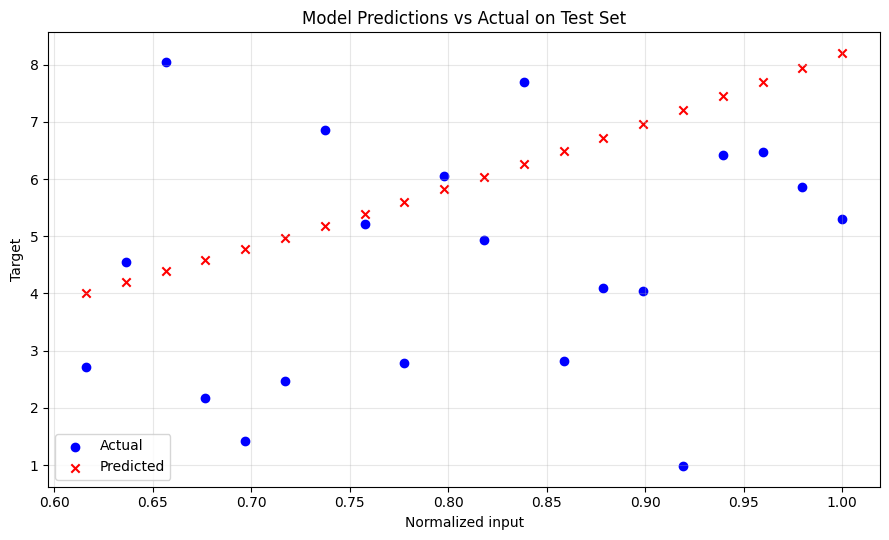

In [8]:
# Plot predictions vs actual values on test set
plt.scatter(X_test, y_test, label="Actual", color="blue")
plt.scatter(X_test, y_pred_test, label="Predicted", color="red", marker="x")
plt.title("Model Predictions vs Actual on Test Set")
plt.xlabel("Normalized input")
plt.ylabel("Target")
plt.legend()
plt.grid(True)
save_figure(plt.gcf(), "test_predictions.png")
plt.show()
plt.close()

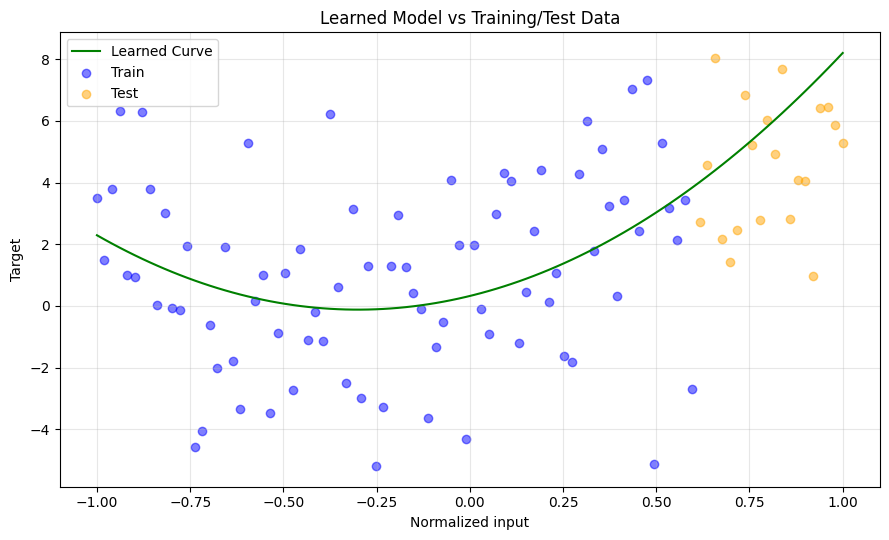

In [9]:
# Overlay learned model curve on all data
X_all_sorted = np.sort(X_scaled)
y_fit_all = predict(X_all_sorted, theta_final)

plt.plot(X_all_sorted, y_fit_all, label="Learned Curve", color="green")
plt.scatter(X_train, y_train, label="Train", alpha=0.5, color="blue")
plt.scatter(X_test, y_test, label="Test", alpha=0.5, color="orange")
plt.title("Learned Model vs Training/Test Data")
plt.xlabel("Normalized input")
plt.ylabel("Target")
plt.legend()
plt.grid(True)
save_figure(plt.gcf(), "fitted_quadratic.png")
plt.show()
plt.close()

## Training and Evaluation Results

The printed summary reports the learned coefficients, training MSE, test MSE,
and final gradient norm.

Convergence is determined by the gradient tolerance rather than the appearance
of the loss curve. The library comparisons below provide an independent check
against the least-squares solution.

The fitted coefficients can differ from the data-generating coefficients
because training uses a finite, noisy sample covering only part of the domain.

## Full-Batch Training Loss

Plot training MSE from initialization through the final parameter update.
The horizontal axis counts updates; the initial loss is shown at update zero.

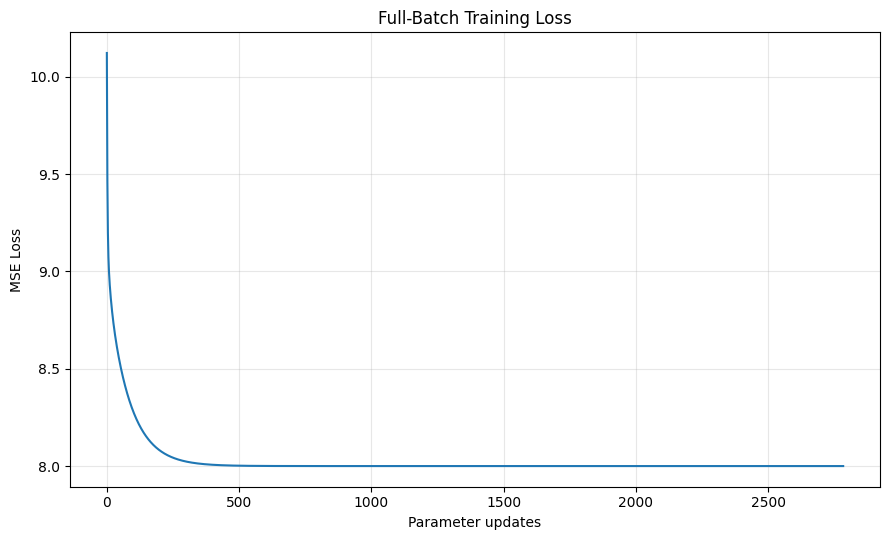

In [10]:
# Plot the recorded full-batch training objective.
plt.plot(loss_history)
plt.title("Full-Batch Training Loss")
plt.xlabel("Parameter updates")
plt.ylabel("MSE Loss")
plt.grid(True)
save_figure(plt.gcf(), "full_batch_training_loss.png")
plt.show()
plt.close()

## Convergence Interpretation

The loss curve shows training MSE from initialization through the final update.
A decreasing curve indicates progress in minimizing the objective.

A visually flat curve alone does not establish convergence. We also inspect
the final gradient norm and compare the fitted solution with reference
least-squares methods.

## Loss Surface and Optimization Trajectory

The model has three parameters, but a contour plot displays two at a time.
We evaluate training MSE across linear and quadratic coefficients while
holding the intercept at its final fitted value.

The overlaid path shows the actual recorded linear and quadratic coefficients
during full-batch training. This is a projection of the three-dimensional
optimization trajectory: the intercept also changed during training.

Consequently, contour values do not represent the actual training loss at
every point along the projected path. The separate loss curve records that
loss directly.

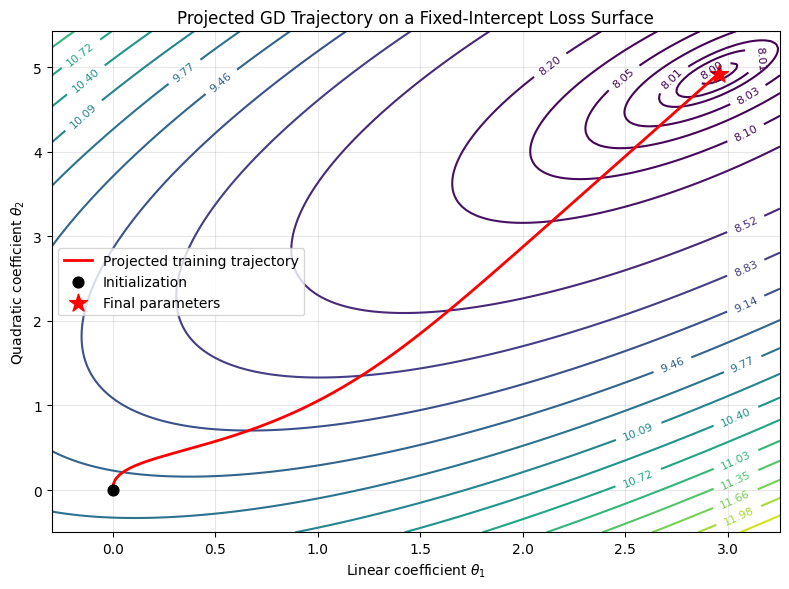

In [11]:
# Use the actual parameter history, including initialization.
theta_path = gd_result["theta_history"]
theta_0_fixed = theta_final[0]

# Include both the trajectory and fitted solution within the plot.
theta1_vals = np.linspace(
    theta_path[:, 1].min() - 0.3,
    theta_path[:, 1].max() + 0.3,
    150,
)
theta2_vals = np.linspace(
    theta_path[:, 2].min() - 0.5,
    theta_path[:, 2].max() + 0.5,
    150,
)
T1, T2 = np.meshgrid(theta1_vals, theta2_vals)

# Evaluate the fixed-intercept loss surface one row at a time.
loss_surface = np.empty_like(T1)

for row in range(T1.shape[0]):
    predictions = (
        theta_0_fixed
        + X_train[:, None] * T1[row]
        + X_train[:, None]**2 * T2[row]
    )
    loss_surface[row] = np.mean(
        (predictions - y_train[:, None])**2,
        axis=0,
    )

fig, ax = plt.subplots(figsize=(8, 6))

contours = ax.contour(
    T1, T2, loss_surface,
    levels=np.concatenate((
        loss_surface.min() + np.array([0.001, 0.005, 0.01, 0.025, 0.05, 0.1]),
        np.linspace(loss_surface.min() + 0.2, loss_surface.max(), 15),
    )),
    cmap="viridis",
)
ax.clabel(contours, inline=True, fontsize=8, fmt="%.2f")

ax.plot(
    theta_path[:, 1],
    theta_path[:, 2],
    color="red",
    linewidth=2,
    label="Projected training trajectory",
)
ax.scatter(
    theta_path[0, 1], theta_path[0, 2],
    color="black", marker="o", s=60,
    label="Initialization", zorder=3,
)
ax.scatter(
    theta_final[1], theta_final[2],
    color="red", marker="*", s=180,
    label="Final parameters", zorder=3,
)

ax.set(
    title="Projected GD Trajectory on a Fixed-Intercept Loss Surface",
    xlabel=r"Linear coefficient $\theta_1$",
    ylabel=r"Quadratic coefficient $\theta_2$",
)
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
save_figure(plt.gcf(), "parameter_trajectory.png")
plt.show()
plt.close()

## Trajectory Interpretation

The recorded coefficients move from zero initialization to approximately
(2.956, 4.925). The intercept changes along this path, so it is a projection
onto the fixed-intercept contour surface rather than a two-parameter training
run. The gradient check and reference comparisons provide the numerical
evidence for convergence.

## Comparison with Reference Solvers

NumPy's polynomial fitting and SciPy's curve fitting solve the same
unregularized quadratic least-squares problem as our custom model.

For comparison, all coefficients are reported in the same order:
intercept, linear term, quadratic term.

A converged gradient descent solution should closely match these reference
solutions in coefficients, predictions, and MSE. Small differences can result
from numerical precision and stopping tolerances.

In [12]:
from scipy.optimize import curve_fit

# NumPy returns polynomial coefficients in descending power order.
np_coeffs = np.polyfit(X_train, y_train, deg=2)
theta_np = np_coeffs[::-1]
y_pred_np = np.polyval(np_coeffs, X_test)
mse_np = mse_loss(y_test, y_pred_np)


def quadratic_model(x, a, b, c):
    """Evaluate a quadratic with coefficients in descending power order."""
    return a * x**2 + b * x + c


# Convert SciPy's [quadratic, linear, intercept] order for reporting.
scipy_params, _ = curve_fit(quadratic_model, X_train, y_train)
theta_scipy = scipy_params[::-1]
y_pred_scipy = quadratic_model(X_test, *scipy_params)
mse_scipy = mse_loss(y_test, y_pred_scipy)

print("Coefficient order: [intercept, linear, quadratic]")
print("Manual GD:    ", theta_final)
print("NumPy polyfit:", theta_np)
print("SciPy fit:    ", theta_scipy)

print(f"\nManual GD test MSE:     {test_mse:.6f}")
print(f"NumPy polyfit test MSE: {mse_np:.6f}")
print(f"SciPy fit test MSE:     {mse_scipy:.6f}")

print(
    "\nMaximum test prediction difference (GD vs NumPy):",
    f"{np.max(np.abs(y_pred_test - y_pred_np)):.3e}",
)

# Verify convergence against an independent least-squares implementation.
np.testing.assert_allclose(
    theta_final, theta_np, rtol=1e-5, atol=1e-6
)
np.testing.assert_allclose(
    y_pred_test, y_pred_np, rtol=1e-5, atol=1e-6
)
np.testing.assert_allclose(
    theta_scipy, theta_np, rtol=1e-5, atol=1e-6
)
print("Gradient descent and SciPy match the NumPy reference solution.")

Coefficient order: [intercept, linear, quadratic]
Manual GD:     [0.32402999 2.95558955 4.92498121]
NumPy polyfit: [0.32402997 2.95558962 4.92498135]
SciPy fit:     [0.32402997 2.95558961 4.92498137]

Manual GD test MSE:     6.777249
NumPy polyfit test MSE: 6.777250
SciPy fit test MSE:     6.777250

Maximum test prediction difference (GD vs NumPy): 1.867e-07
Gradient descent and SciPy match the NumPy reference solution.


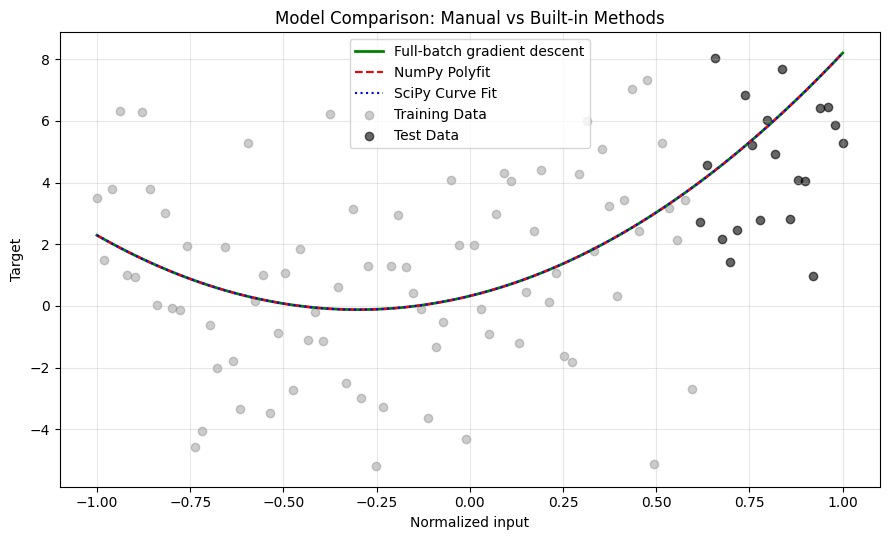

In [13]:
# Sort full scaled X for smooth plotting
X_all_sorted = np.sort(X_scaled)

# Predictions from each model on full range
y_pred_manual = predict(X_all_sorted, theta_final)
y_pred_np_full = np.polyval(np_coeffs, X_all_sorted)
y_pred_scipy_full = quadratic_model(X_all_sorted, *scipy_params)

# Plot all predictions
plt.plot(X_all_sorted, y_pred_manual, label="Full-batch gradient descent", color="green", linewidth=2)
plt.plot(X_all_sorted, y_pred_np_full, label="NumPy Polyfit", linestyle="--", color="red")
plt.plot(X_all_sorted, y_pred_scipy_full, label="SciPy Curve Fit", linestyle=":", color="blue")

# Plot original noisy data
plt.scatter(X_train, y_train, color='gray', alpha=0.4, label="Training Data")
plt.scatter(X_test, y_test, color='black', alpha=0.6, label="Test Data")

plt.title("Model Comparison: Manual vs Built-in Methods")
plt.xlabel("Normalized input")
plt.ylabel("Target")
plt.legend()
plt.grid(True)
save_figure(plt.gcf(), "reference_solver_comparison.png")
plt.show()
plt.close()

## Scikit-learn Reference Model

PolynomialFeatures constructs the linear and quadratic features.
LinearRegression fits their coefficients and a separate intercept.

We exclude the constant feature to avoid duplicating the intercept.
This model solves the same unregularized least-squares problem as NumPy,
SciPy, and converged full-batch gradient descent.

In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

# LinearRegression handles the intercept separately.
poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train.reshape(-1, 1))
X_test_poly = poly.transform(X_test.reshape(-1, 1))

model = LinearRegression()
model.fit(X_train_poly, y_train)

theta_sklearn = np.concatenate((
    [model.intercept_],
    model.coef_,
))

y_pred_sklearn = model.predict(X_test_poly)
mse_sklearn = mse_loss(y_test, y_pred_sklearn)

np.testing.assert_allclose(
    theta_sklearn, theta_np, rtol=1e-5, atol=1e-6
)
np.testing.assert_allclose(
    y_pred_sklearn, y_pred_test, rtol=1e-5, atol=1e-6
)

print("Coefficient order: [intercept, linear, quadratic]")
print("Scikit-learn parameters:", theta_sklearn)
print(f"Test MSE: {mse_sklearn:.6f}")
print("Scikit-learn matches NumPy and converged gradient descent.")

Coefficient order: [intercept, linear, quadratic]
Scikit-learn parameters: [0.32402997 2.95558962 4.92498135]
Test MSE: 6.777250
Scikit-learn matches NumPy and converged gradient descent.


## Mini-Batch Gradient Descent

Full-batch gradient descent uses all training observations per update.
Mini-batch gradient descent updates parameters using smaller subsets.

At each epoch, we shuffle the training observations and process every batch
once. An epoch therefore represents one complete pass through the training
data, while each batch produces a separate parameter update.

A dedicated random generator makes batch ordering reproducible. We record
full-training MSE after each epoch to monitor progress.

In [15]:
def mini_batch_gradient_descent(
    X, y, lr=0.01, epochs=5000, batch_size=16, seed=42
):
    """Fit quadratic regression using shuffled mini-batches."""
    rng = np.random.default_rng(seed)
    theta = np.zeros(3, dtype=float)
    history = [mse_loss(y, predict(X, theta))]
    n_updates = 0
    n = len(y)

    for _ in range(epochs):
        indices = rng.permutation(n)

        for start in range(0, n, batch_size):
            batch_indices = indices[start:start + batch_size]
            grads = compute_gradients(
                X[batch_indices], y[batch_indices], theta
            )
            theta -= lr * grads
            n_updates += 1

            if not np.all(np.isfinite(theta)):
                raise FloatingPointError(
                    "Mini-batch training diverged. "
                    "Try a smaller learning rate."
                )

        loss = mse_loss(y, predict(X, theta))

        if not np.isfinite(loss):
            raise FloatingPointError("Non-finite training loss encountered.")

        history.append(loss)

    return {
        "theta": theta,
        "loss_history": np.array(history),
        "n_epochs": epochs,
        "n_updates": n_updates,
    }

In [16]:
mb_result = mini_batch_gradient_descent(
    X_train, y_train,
    lr=0.01,
    epochs=5000,
    batch_size=16,
    seed=42,
)

# Extract fitted parameters and epoch-level training loss.
theta_mb = mb_result["theta"]
history_mb = mb_result["loss_history"]

y_pred_mb = predict(X_test, theta_mb)
train_mse_mb = mse_loss(y_train, predict(X_train, theta_mb))
test_mse_mb = mse_loss(y_test, y_pred_mb)

print("Mini-batch parameters:", theta_mb)
print(f"Training MSE: {train_mse_mb:.6f}")
print(f"Test MSE: {test_mse_mb:.6f}")
print("Epochs:", mb_result["n_epochs"])
print("Parameter updates:", mb_result["n_updates"])

print(f"\nFull-batch training MSE: {train_mse:.6f}")
print(f"Full-batch test MSE: {test_mse:.6f}")

print(
    "Maximum coefficient difference from NumPy:",
    f"{np.max(np.abs(theta_mb - theta_np)):.6f}",
)

Mini-batch parameters: [0.32736166 2.95467876 4.92696688]
Training MSE: 8.000626
Test MSE: 6.789099
Epochs: 5000
Parameter updates: 25000

Full-batch training MSE: 8.000609
Full-batch test MSE: 6.777249
Maximum coefficient difference from NumPy: 0.003332


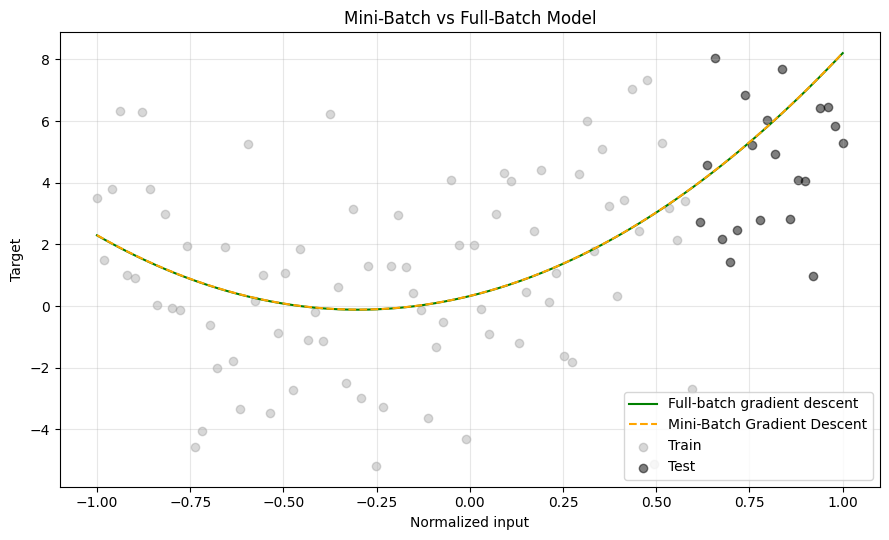

In [17]:
# Predict on full sorted X for both models
y_pred_manual = predict(X_all_sorted, theta_final)
y_pred_mini_batch = predict(X_all_sorted, theta_mb)

# Plot both models
plt.plot(X_all_sorted, y_pred_manual, label="Full-batch gradient descent", color="green")
plt.plot(X_all_sorted, y_pred_mini_batch, label="Mini-Batch Gradient Descent", color="orange", linestyle="--")

# Scatter data
plt.scatter(X_train, y_train, alpha=0.3, label="Train", color='gray')
plt.scatter(X_test, y_test, alpha=0.5, label="Test", color='black')

plt.title("Mini-Batch vs Full-Batch Model")
plt.xlabel("Normalized input")
plt.ylabel("Target")
plt.legend()
plt.grid(True)
save_figure(plt.gcf(), "mini_batch_comparison.png")
plt.show()
plt.close()

## Mini-Batch Results Interpretation

Mini-batch training approximates the same least-squares solution as full-batch
gradient descent. With a fixed learning rate, individual batch updates can
continue to fluctuate near the optimum.

Compare training MSE with the converged full-batch result to assess optimization
accuracy. A small difference in test MSE on one split does not establish that
either method generalizes better.

The methods use different numbers of observations per update, so update counts
alone do not establish computational efficiency. No runtime advantage is
claimed in this experiment.

## L2-Regularized Regression

L2 regularization discourages large linear and quadratic coefficients:

$$
J(\theta) = \frac{1}{n}\sum_i(\hat{y}_i-y_i)^2
+ \lambda(\theta_1^2+\theta_2^2)
$$

The intercept is not penalized.

The gradient equals the MSE gradient plus
$2\lambda[0,\theta_1,\theta_2]$.

We use a fixed penalty strength of 0.1 to illustrate coefficient shrinkage.
This value is not selected through hyperparameter tuning. Training minimizes
the penalized objective, while test evaluation reports ordinary MSE.

In [18]:
def gradient_descent_l2(
    X, y, lr=0.1, max_updates=20000, lambda_reg=0.1, tol=1e-8
):
    """Fit quadratic regression with L2 penalties excluding the intercept."""
    theta = np.zeros(3, dtype=float)

    def objective(theta):
        return (
            mse_loss(y, predict(X, theta))
            + lambda_reg * np.sum(theta[1:]**2)
        )

    history = [objective(theta)]

    for _ in range(max_updates):
        grads = compute_gradients(X, y, theta)
        grads[1:] += 2.0 * lambda_reg * theta[1:]

        if not np.all(np.isfinite(grads)):
            raise FloatingPointError("Non-finite regularized gradients.")

        if np.linalg.norm(grads) <= tol:
            break

        theta -= lr * grads
        loss = objective(theta)

        if not np.isfinite(loss):
            raise FloatingPointError(
                "Regularized training diverged. Try a smaller learning rate."
            )

        history.append(loss)

    final_grads = compute_gradients(X, y, theta)
    final_grads[1:] += 2.0 * lambda_reg * theta[1:]
    gradient_norm = np.linalg.norm(final_grads)

    return {
        "theta": theta,
        "objective_history": np.array(history),
        "n_updates": len(history) - 1,
        "gradient_norm": gradient_norm,
        "converged": gradient_norm <= tol,
    }

In [19]:
LAMBDA_REG = 0.1

l2_result = gradient_descent_l2(
    X_train, y_train,
    lr=0.1,
    max_updates=20000,
    lambda_reg=LAMBDA_REG,
    tol=1e-8,
)

theta_l2 = l2_result["theta"]
history_l2 = l2_result["objective_history"]

y_pred_l2 = predict(X_test, theta_l2)
train_mse_l2 = mse_loss(y_train, predict(X_train, theta_l2))
test_mse_l2 = mse_loss(y_test, y_pred_l2)

# Independent solution of the same regularized least-squares objective.
A = design_matrix(X_train)
penalty_matrix = np.diag([0.0, 1.0, 1.0])

theta_l2_reference = np.linalg.solve(
    A.T @ A + len(y_train) * LAMBDA_REG * penalty_matrix,
    A.T @ y_train,
)

np.testing.assert_allclose(
    theta_l2, theta_l2_reference,
    rtol=1e-5, atol=1e-6,
)

print("L2 parameters:", theta_l2)
print("Direct reference:", theta_l2_reference)
print(f"Training MSE: {train_mse_l2:.6f}")
print(f"Test MSE: {test_mse_l2:.6f}")
print(f"Final penalized objective: {history_l2[-1]:.6f}")
print("Parameter updates:", l2_result["n_updates"])
print(f"Final gradient norm: {l2_result['gradient_norm']:.3e}")
print("Converged:", l2_result["converged"])

print(
    "\nUnregularized slope coefficient norm:",
    f"{np.linalg.norm(theta_final[1:]):.6f}",
)
print(
    "Regularized slope coefficient norm:",
    f"{np.linalg.norm(theta_l2[1:]):.6f}",
)
print("Regularized GD matches the direct reference solution.")

L2 parameters: [0.9163425  0.95843197 1.07198993]
Direct reference: [0.91634249 0.95843199 1.07198997]
Training MSE: 8.605059
Test MSE: 8.515031
Final penalized objective: 8.811835
Parameter updates: 663
Final gradient norm: 9.800e-09
Converged: True

Unregularized slope coefficient norm: 5.743775
Regularized slope coefficient norm: 1.437969
Regularized GD matches the direct reference solution.


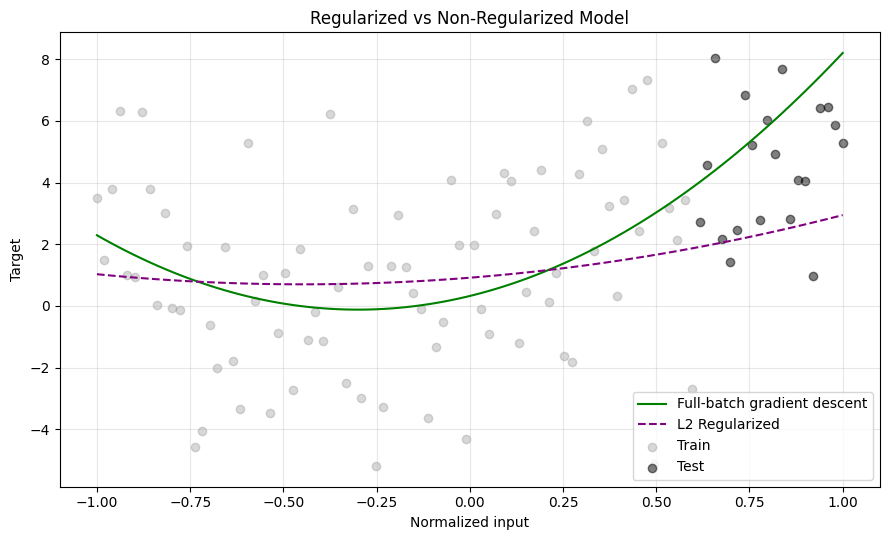

In [20]:
# Predictions on full range
y_pred_l2_full = predict(X_all_sorted, theta_l2)
y_pred_manual = predict(X_all_sorted, theta_final)

# Plot regularized vs original
plt.plot(X_all_sorted, y_pred_manual, label="Full-batch gradient descent", color="green")
plt.plot(X_all_sorted, y_pred_l2_full, label="L2 Regularized", color="purple", linestyle="--")

# Data points
plt.scatter(X_train, y_train, alpha=0.3, label="Train", color='gray')
plt.scatter(X_test, y_test, alpha=0.5, label="Test", color='black')

plt.title("Regularized vs Non-Regularized Model")
plt.xlabel("Normalized input")
plt.ylabel("Target")
plt.legend()
plt.grid(True)
save_figure(plt.gcf(), "l2_regularization_comparison.png")
plt.show()
plt.close()

## Regularization Interpretation

Compare the coefficient norms to assess shrinkage and test MSE to assess
prediction error on the held-out input range.

Regularization trades a closer training fit for smaller coefficients.
It does not guarantee improved test performance, particularly when the
penalty strength has not been tuned.

The penalized training objective differs from ordinary MSE and should not
be compared directly with the unregularized model's training MSE.

Agreement with the direct regularized solution verifies optimization of
the stated objective.

With λ = 0.1, the norm of the linear and quadratic coefficients decreased
from 5.744 to 1.438. Training MSE increased from 8.001 to 8.605, and test
MSE increased from 6.777 to 8.515. This penalty therefore reduced coefficient
magnitudes but worsened prediction accuracy on the held-out extrapolation
region.

## Results Summary

The table below compares all methods using the same training and test
observations. Coefficients are expressed in the normalized input space.

Full-batch gradient descent, NumPy, SciPy, and scikit-learn solve the same
unregularized least-squares problem. Mini-batch training approximates that
solution through smaller updates. L2 regression optimizes a different,
penalized objective.

Training and test columns report ordinary MSE for every method.

In [21]:
from IPython.display import Markdown, display

results = [
    ("Full-batch GD", theta_final),
    ("Mini-batch GD", theta_mb),
    ("L2 GD (lambda=0.1)", theta_l2),
    ("NumPy polyfit", theta_np),
    ("SciPy curve_fit", theta_scipy),
    ("Scikit-learn", theta_sklearn),
]

table_lines = [
    "| Method | Intercept | Linear | Quadratic | Training MSE | Test MSE |",
    "|---|---:|---:|---:|---:|---:|",
]

for name, theta in results:
    training_error = mse_loss(y_train, predict(X_train, theta))
    test_error = mse_loss(y_test, predict(X_test, theta))

    table_lines.append(
        f"| {name} | {theta[0]:.6f} | {theta[1]:.6f} | "
        f"{theta[2]:.6f} | {training_error:.6f} | {test_error:.6f} |"
    )

display(Markdown("\n".join(table_lines)))

| Method | Intercept | Linear | Quadratic | Training MSE | Test MSE |
|---|---:|---:|---:|---:|---:|
| Full-batch GD | 0.324030 | 2.955590 | 4.924981 | 8.000609 | 6.777249 |
| Mini-batch GD | 0.327362 | 2.954679 | 4.926967 | 8.000626 | 6.789099 |
| L2 GD (lambda=0.1) | 0.916342 | 0.958432 | 1.071990 | 8.605059 | 8.515031 |
| NumPy polyfit | 0.324030 | 2.955590 | 4.924981 | 8.000609 | 6.777250 |
| SciPy curve_fit | 0.324030 | 2.955590 | 4.924981 | 8.000609 | 6.777250 |
| Scikit-learn | 0.324030 | 2.955590 | 4.924981 | 8.000609 | 6.777250 |

## Conclusions and Limitations

- The analytical gradients agree with finite-difference approximations.
- Full-batch gradient descent reaches the gradient tolerance and closely
  matches the unregularized reference solvers.
- Mini-batch training uses complete shuffled epochs. Its fixed learning rate
  can produce fluctuations near the optimum.
- L2 regression matches its direct reference solution. With λ = 0.1, it
  shrinks the coefficients but increases test MSE in this experiment.

The experiment uses one synthetic dataset, one noise realization, and one
ordered split with 20 test observations. Evaluation measures extrapolation
over the held-out upper input range. These results do not establish
performance on other datasets or input domains.

Potential extensions include repeated experiments across random seeds,
separate interpolation and extrapolation evaluations, learning-rate
comparisons, and regularization tuning using validation data rather
than the test set.